## Configuration

In [21]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..") 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import cfg

cfg.ensure_dirs()
TARGET = cfg.TARGET_COL
ORDER = cfg.TARGET_CLASSES
from IPython.display import Image, display

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Préparation (split 80/20 stratifié)

In [ ]:
from src.train import step_prepare


paths = step_prepare()
train = pd.read_csv(paths["train"])
test = pd.read_csv(paths["test"])

print(train.shape, test.shape)

pd.DataFrame({
    "train": train[TARGET].value_counts(normalize=True),
    "test": test[TARGET].value_counts(normalize=True)
    }).reindex(ORDER).round(3)

2026-11-11 16:53:01,425 | INFO | src.data_loader | Données chargées : 2000 lignes x 17 colonnes
2026-11-11 16:53:01,432 | INFO | src.data_loader | Fin du nettoyage : 2000 lignes x 16 colonnes (0 lignes supprimées au total)
2026-11-11 16:53:01,448 | INFO | src.train | Train : 1600 lignes | Test : 400 lignes


(1600, 16) (400, 16)


,train,test
Mental_Health_Risk,,
Low,0.33,0.33
Medium,0.33,0.33
High,0.34,0.34


##  Entraînement, comparaison et optimisation

- 3 modèles + une baseline, même pipeline, même jeu d'entraînement
- Validation croisée stratifiée (5 folds)
- `RandomizedSearchCV` sur les 2 meilleurs modèles
- Le meilleur pipeline complet est sauvegardé dans `models/`

In [23]:
from src.train import step_train

model_path = step_train(paths["train"])

2026-11-11 16:53:09,053 | INFO | src.train | CV dummy_baseline       f1_macro = 0.169
2026-11-11 16:53:09,785 | INFO | src.train | CV logistic_regression  f1_macro = 0.748
2026-11-11 16:53:10,714 | INFO | src.train | CV random_forest        f1_macro = 0.672
2026-11-11 16:53:10,802 | INFO | src.train | CV decision_tree        f1_macro = 0.574
2026-11-11 16:53:11,686 | INFO | src.train | Tuning logistic_regression  best f1_macro = 0.752
2026-11-11 16:53:25,220 | INFO | src.train | Tuning random_forest        best f1_macro = 0.681
2026-11-11 16:53:25,230 | INFO | src.train | Modèle sauvegardé : /home/ouelaimar/Desktop/student-mh-risk-predictor/models/model_pipeline.joblib (logistic_regression)


In [24]:
cv = pd.read_csv(cfg.CV_RESULTS_PATH).set_index("model")
cv.round(3)

,fit_time_s,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
model,,,,,,,,,
logistic_regression,0.73,0.749,0.021,0.749,0.023,0.748,0.021,0.748,0.022
random_forest,0.93,0.675,0.028,0.672,0.026,0.674,0.028,0.672,0.027
decision_tree,0.09,0.574,0.028,0.576,0.022,0.573,0.028,0.574,0.025
dummy_baseline,1.19,0.340,0.001,0.113,0.000,0.333,0.000,0.169,0.000


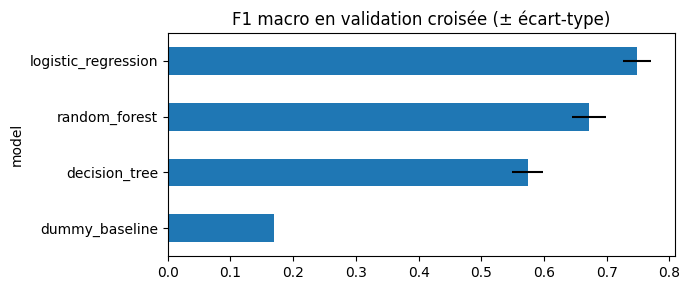

In [26]:
%matplotlib inline
ax = cv["f1_macro_mean"].sort_values().plot(kind="barh", xerr=cv["f1_macro_std"], figsize=(7, 3))
ax.set_title("F1 macro en validation croisée (± écart-type)")
plt.tight_layout()

plt.show()

In [27]:
import json

tuning = json.loads(cfg.TUNING_RESULTS_PATH.read_text())
pd.DataFrame({k: {"meilleur score CV": v["best_score"], "durée (s)": v["search_time_s"]}
              for k, v in tuning.items()}).T

,meilleur score CV,durée (s)
logistic_regression,0.751833,0.88
random_forest,0.681088,13.53


In [28]:
for name, res in tuning.items():
    print(name, res["best_params"])

logistic_regression {'model__C': 14.528246637516036, 'model__class_weight': 'balanced'}
random_forest {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 20}


## Évaluation

In [29]:
from src.train import step_evaluate

metrics = step_evaluate(model_path, paths["test"])
keys = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr",
        "positive_class_recall", "high_predicted_as_low"]
pd.Series({k: metrics[k] for k in keys}).round(3)

2026-11-11 16:54:00,770 | INFO | src.train | Test : accuracy=0.752 | f1_macro=0.752 | rappel High=0.816


accuracy                 0.752
precision_macro          0.753
recall_macro             0.752
f1_macro                 0.752
roc_auc_ovr              0.913
positive_class_recall    0.816
high_predicted_as_low    0.000
dtype: float64

In [30]:
pd.DataFrame(metrics["classification_report"]).T.round(3)

,precision,recall,f1-score,support
Low,0.822,0.803,0.812,132.000
Medium,0.627,0.636,0.632,132.000
High,0.810,0.816,0.813,136.000
accuracy,0.752,0.752,0.752,0.752
macro avg,0.753,0.752,0.752,400.000
weighted avg,0.754,0.752,0.753,400.000


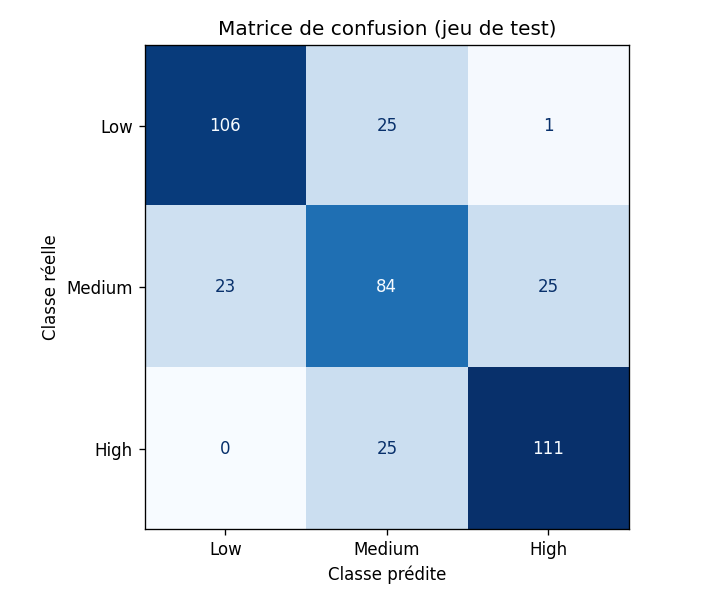

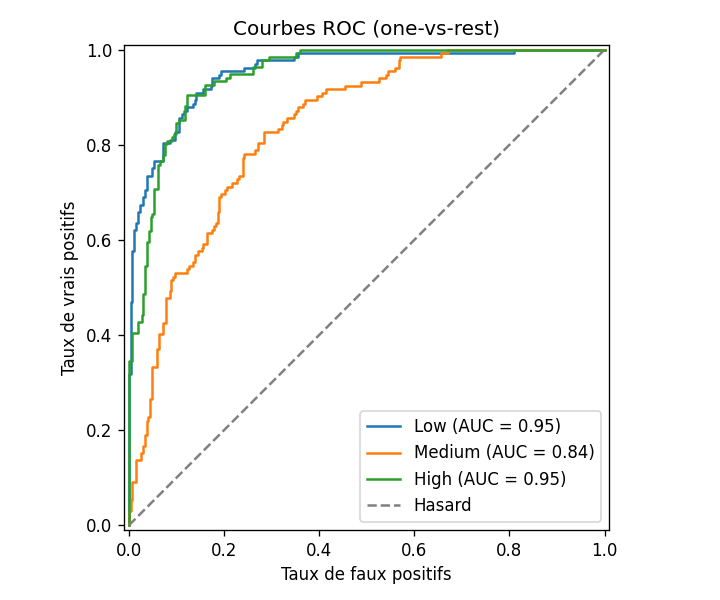

In [31]:
display(Image(cfg.FIGURES_DIR / "confusion_matrix.png"))
display(Image(cfg.FIGURES_DIR / "roc_curves.png"))

In [32]:
# Comparaison CV vs test : un écart important signalerait du sur-apprentissage
meta = json.loads(cfg.METADATA_PATH.read_text())
print(f"F1 macro CV   : {meta['cv_score']:.3f}")
print(f"F1 macro test : {metrics['f1_macro']:.3f}")

F1 macro CV   : 0.752
F1 macro test : 0.752


## Analyse des erreurs

In [33]:
pred = pd.read_csv(cfg.TEST_PREDICTIONS_PATH)
pred["correct"] = pred["y_true"] == pred["y_pred"]
pred["confidence"] = pred[[f"proba_{c}" for c in ORDER]].max(axis=1)
print(f"Erreurs : {(~pred.correct).sum()} / {len(pred)}")
pd.crosstab(pred.y_true, pred.y_pred).reindex(index=ORDER, columns=ORDER)

Erreurs : 99 / 400


y_pred,Low,Medium,High
y_true,,,
Low,106,25,1
Medium,23,84,25
High,0,25,111


In [34]:
# Confiance du modèle : les erreurs sont-elles des cas incertains ?
pred.groupby("correct")["confidence"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
False,99.0,0.670,0.131,0.482,0.577,0.654,0.755,0.966
True,301.0,0.825,0.151,0.501,0.713,0.844,0.978,1.000


In [35]:
# Profil des étudiants à risque élevé manqués (faux négatifs) vs bien détectés
high = pred[pred.y_true == "High"]
numeric = [c for c in meta["numeric_features"]]
high.groupby(high.y_pred == "High")[numeric].median().T.rename(
    columns={True: "High détectés", False: "High manqués"}).round(2)

y_pred,High manqués,High détectés
Age,22.00,21.00
Year_of_Study,2.00,2.00
Sleep_Hours,6.90,6.00
Study_Hours_Per_Week,19.70,17.90
GPA,2.56,2.38
Social_Media_Hours,6.10,6.20
Screen_Time_Hours,9.30,9.00
Financial_Stress,6.70,7.10
Family_Support,6.05,5.80
Attendance_Rate,84.10,84.35


In [36]:
high[high.y_pred != "High"].head(10)

,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,...,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,y_true,y_pred,proba_Low,proba_Medium,proba_High,correct,confidence
9,23,Male,1,7.8,4.9,2.15,6.3,9.9,Low,6.1,...,Yes,Good,No,High,Medium,0.1132,0.7748,0.1121,False,0.7748
55,20,Male,2,6.1,21.9,2.53,4.7,9.7,Moderate,5.1,...,No,Average,Yes,High,Medium,0.0114,0.4957,0.4929,False,0.4957
92,18,Female,1,5.8,18.1,2.87,6.1,10.2,Moderate,NaN,...,No,Good,No,High,Medium,0.4046,0.5335,0.0620,False,0.5335
115,22,Female,5,7.4,20.8,2.59,5.3,7.6,High,7.3,...,Yes,Poor,Yes,High,Medium,0.0112,0.5876,0.4012,False,0.5876
119,24,Male,2,6.9,19.7,2.72,5.4,9.4,Moderate,6.6,...,No,Average,No,High,Medium,0.2568,0.6877,0.0554,False,0.6877
120,22,Male,5,7.0,29.3,2.66,3.7,5.9,Low,7.0,...,Yes,Average,No,High,Medium,0.0426,0.7537,0.2037,False,0.7537
140,21,Male,2,6.5,20.4,2.39,6.3,9.8,Moderate,4.3,...,No,Average,No,High,Medium,0.1422,0.7422,0.1155,False,0.7422
143,21,Male,4,6.6,18.1,2.56,6.8,11.4,Moderate,8.3,...,No,Average,No,High,Medium,0.0358,0.5262,0.4380,False,0.5262
144,19,Male,3,5.9,21.0,2.99,5.3,7.7,High,8.5,...,No,Average,Yes,High,Medium,0.0148,0.5041,0.4812,False,0.5041
150,17,Male,1,4.2,21.1,2.37,5.3,8.5,High,6.7,...,No,Average,No,High,Medium,0.0344,0.5821,0.3835,False,0.5821


## Importance des variables

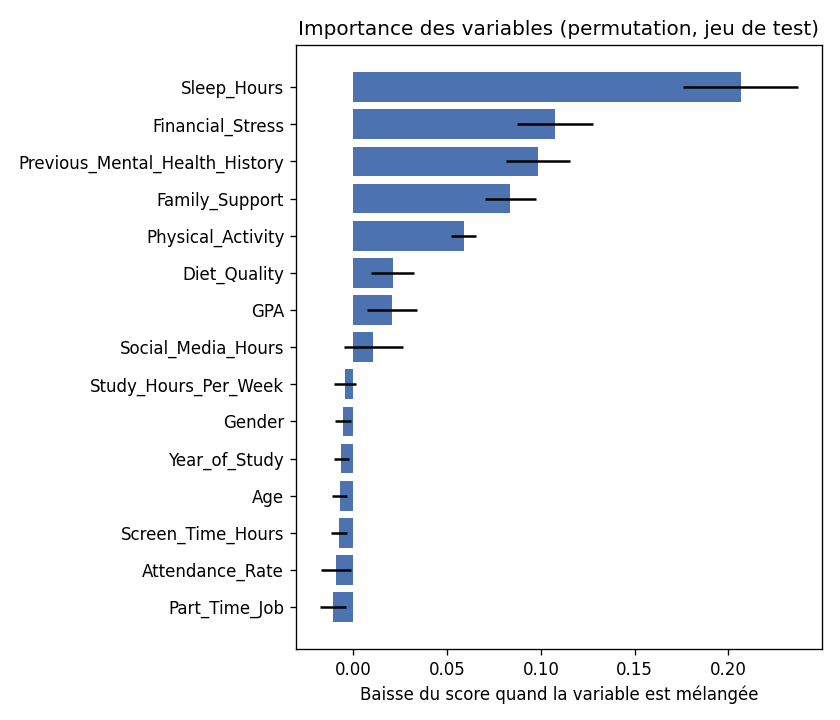

,feature,importance_mean,importance_std
0,Sleep_Hours,0.2064,0.0307
1,Financial_Stress,0.1077,0.0204
2,Previous_Mental_Health_History,0.0986,0.0169
3,Family_Support,0.0837,0.0138
4,Physical_Activity,0.0590,0.0067
5,Diet_Quality,0.0210,0.0117
6,GPA,0.0206,0.0133
7,Social_Media_Hours,0.0108,0.0156
8,Study_Hours_Per_Week,-0.0043,0.0060
9,Gender,-0.0054,0.0042


In [37]:
display(Image(cfg.FIGURES_DIR / "feature_importance.png"))
pd.read_csv(cfg.FEATURE_IMPORTANCE_PATH).round(4)

## 6. Conclusion et limites
**Modèle retenu et justification** : Régression logistique (logistic_regression, class_weight="balanced", C ≈ 14,53), sélectionnée après validation croisée stratifiée (5 folds) et recherche d’hyperparamètres sur le jeu d’entraînement (1 600 observations, scoring : F1-macro).  
- Performance en CV : F1-macro moyen = 0,748 (accuracy = 0,749) ; après tuning, meilleur score CV F1-macro = 0,752.  
- Comparaison : elle surpasse la forêt aléatoire (F1-macro CV ≈ 0,672 ; meilleur tuning = 0,681), l’arbre de décision (≈ 0,574) et la baseline aléatoire stratifiée (≈ 0,169).  
- Choix : meilleur compromis performance/stabilité sur la métrique d’intérêt (F1-macro, adaptée au caractère multi-classe et au déséquilibre), avec un modèle linéaire interprétable et des poids de classe compensant le déséquilibre.

**Résultats sur le test (n = 400, évaluation du 2026-11-11)** :

- Global : accuracy = 0,753, précision macro = 0,753, rappel macro = 0,752, F1-macro = 0,752, F1 pondéré = 0,753, ROC-AUC (OvR) = 0,913.
- Par classe :
- Low : précision 0,822 · rappel 0,803 · F1 0,812 (support 132)
- Medium : précision 0,627 · rappel 0,636 · F1 0,632 (support 132)
- High : précision 0,810 · rappel 0,816 · F1 0,813 (support 136)
- Lecture : bonnes performances sur les classes Low et High ; la classe Medium reste la plus difficile (confusions principalement avec Low et High, cf. matrice de confusion). Aucun individu High n’a été prédit Low (high_predicted_as_low = 0), ce qui est favorable du point de vue du risque de sous-estimation extrême, sans constituer une garantie.

**Limites** :

- Données synthétiques : la cible provient d’un score pondéré avec du bruit ; les performances ne se transfèrent pas à de vrais étudiants.
- Variables auto-déclarées (stress, soutien, alimentation, etc.) : biais de déclaration et de mesure possibles.
- Association statistique ≠ causalité : le modèle capture des corrélations, pas des mécanismes explicatifs.
- Performance hétérogène selon les classes (classe Medium nettement moins bien prédite) et risque de biais selon les groupes (genre, âge, etc.) à vérifier avant tout usage.
- Évaluation sur un unique jeu de test issu de la même distribution synthétique : absence de validation externe.
Usage : prototype pédagogique uniquement, jamais un outil de diagnostic, de dépistage clinique ou de décision individuelle. Toute utilisation réelle nécessiterait des données cliniques/terrain validées, une évaluation éthique et de biais, une validation externe et un encadrement humain qualifié.